# 03 · Líneas base B0–B3
TA Aprendizaje de Máquina, grupo 5. Entregable 2.

**Objetivo.** Medir las cuatro líneas base del diseño experimental en cada corte k, con los mismos pliegues de validación y el mismo conjunto de prueba que usarán los modelos.

- B0: predecir "a tiempo" (0 min).
- B1: mediana del atraso final en entrenamiento por hora de inicio y día de la semana (si la combinación no existe, mediana por hora y luego global).
- B2: persistencia, el atraso final es igual al último atraso observado hasta el punto k (0 si no hay ninguno).
- B3: regresión lineal con solo el último atraso observado.

**Entradas:** `data/processed/corte_k{k}.pkl`. **Salidas:** `results/tables/03_lineas_base.csv`, `results/figures/03_lineas_base_vs_k.png`, `data/processed/03_pred_test.pkl`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

RAIZ = Path("..")
sys.path.insert(0, str(RAIZ.resolve()))
from src.variables import CORTES
from src.particion import N_PLIEGUES
from src.evaluacion import metricas_regresion
from src import graficos

SEMILLA = 42
DIR_PROC = RAIZ / "data" / "processed"
DIR_FIG = RAIZ / "results" / "figures"
DIR_TAB = RAIZ / "results" / "tables"
graficos.estilo()

## 1. Definición de las líneas base
Cada línea base se "ajusta" solo con las filas de entrenamiento que recibe.

In [2]:
def b0(ent, ev):
    return np.zeros(len(ev))


def b1(ent, ev):
    hora_ent, hora_ev = np.floor(ent["hora_inicio"]), np.floor(ev["hora_inicio"])
    por_hora_dia = ent.groupby([hora_ent, ent["dia_semana"]])["y"].median()
    por_hora = ent.groupby(hora_ent)["y"].median()
    claves = pd.MultiIndex.from_arrays([hora_ev, ev["dia_semana"]])
    pred = pd.Series(por_hora_dia.reindex(claves).to_numpy(), index=ev.index)
    pred = pred.fillna(pd.Series(por_hora.reindex(hora_ev).to_numpy(), index=ev.index))
    return pred.fillna(ent["y"].median()).to_numpy()


def b2(ent, ev):
    return ev["atr_ultimo"].fillna(0).to_numpy()


def b3(ent, ev):
    modelo = make_pipeline(SimpleImputer(strategy="median"), LinearRegression())
    modelo.fit(ent[["atr_ultimo"]], ent["y"])
    return modelo.predict(ev[["atr_ultimo"]])


LINEAS_BASE = {"B0 a tiempo": b0, "B1 mediana hora-día": b1, "B2 persistencia": b2, "B3 lineal atraso k": b3}

## 2. Validación por pliegues y prueba
MAE de validación = promedio de los 4 pliegues de ventana creciente. La prueba se evalúa ajustando con todo el entrenamiento.

In [3]:
filas, predicciones = [], []
for k in CORTES:
    x = pd.read_pickle(DIR_PROC / f"corte_k{k}.pkl")
    tr, te = x[x["conjunto"] == "train"], x[x["conjunto"] == "test"]
    for nombre, f in LINEAS_BASE.items():
        mae_val = [np.mean(np.abs(f(tr[tr["bloque"] < p], tr[tr["bloque"] == p]) - tr.loc[tr["bloque"] == p, "y"]))
                   for p in range(N_PLIEGUES)]
        pred = f(tr, te)
        filas.append({"k": k, "modelo": nombre, "MAE_val": np.mean(mae_val), "MAE_val_std": np.std(mae_val),
                      **metricas_regresion(te["y"], pred)})
        predicciones.append(te[["id", "k", "fecha", "franja", "dia_semana", "y"]].assign(modelo=nombre, pred=pred))

lineas_base = pd.DataFrame(filas)
lineas_base.to_csv(DIR_TAB / "03_lineas_base.csv", index=False, float_format="%.6f")
pd.concat(predicciones, ignore_index=True).to_pickle(DIR_PROC / "03_pred_test.pkl")
lineas_base.pivot(index="modelo", columns="k", values=["MAE_val", "MAE"]).round(2)

MAE_val                           MAE                    \
k                        4     6     9     12    15    4     6     9     12   
modelo                                                                        
B0 a tiempo            6.04  6.04  6.04  6.04  6.04  5.05  5.05  5.05  5.05   
B1 mediana hora-día    3.67  3.67  3.67  3.67  3.67  3.20  3.20  3.20  3.20   
B2 persistencia        5.90  4.69  4.80  4.42  2.77  4.94  3.93  3.93  3.56   
B3 lineal atraso k     5.59  4.46  4.51  4.26  2.80  5.08  3.97  3.99  3.47   

                           
k                      15  
modelo                     
B0 a tiempo          5.05  
B1 mediana hora-día  3.20  
B2 persistencia      2.38  
B3 lineal atraso k   2.35

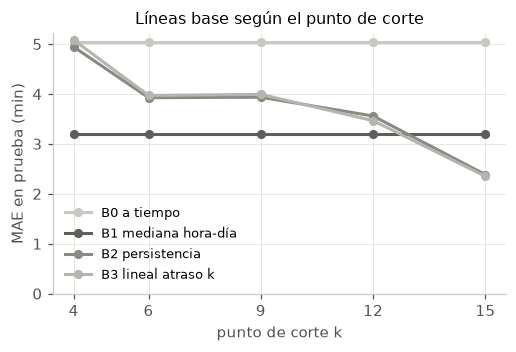

In [4]:
fig, ax = plt.subplots(figsize=(4.8, 3.3))
for nombre in LINEAS_BASE:
    d = lineas_base[lineas_base["modelo"] == nombre]
    ax.plot(d["k"], d["MAE"], marker="o", color=graficos.COLOR_MODELO[nombre], label=nombre)
ax.set(xlabel="punto de corte k", ylabel="MAE en prueba (min)", xticks=CORTES, ylim=(0, None),
       title="Líneas base según el punto de corte")
ax.legend(loc="lower left")
graficos.guardar(fig, DIR_FIG / "03_lineas_base_vs_k.png")

In [5]:
lineas_base[lineas_base["k"] == 9].set_index("modelo").drop(columns="k").round(3)

,MAE_val,MAE_val_std,MAE,MedAE,RMSE,R2,pct_err_2,pct_err_5,n
modelo,,,,,,,,,
B0 a tiempo,6.044,1.698,5.051,3.000,8.053,-0.080,49.576,70.688,1061
B1 mediana hora-día,3.672,0.705,3.201,2.000,4.699,0.632,53.346,81.998,1061
B2 persistencia,4.804,0.971,3.935,3.000,5.751,0.449,47.879,75.024,1061
B3 lineal atraso k,4.510,0.776,3.992,3.021,5.348,0.524,31.103,70.500,1061


## 3. Conclusiones
- B0 ("a tiempo") da un MAE de 5,05 min en prueba, coherente con la referencia preliminar del E1 (5,07).
- B1 (solo horario: mediana por hora de inicio y día) baja a 3,20 min y no depende de k. Es la línea base más exigente hasta k = 12.
- La persistencia (B2) mejora con k: 4,94 min en k = 4, 3,93 en k = 9 y 2,38 en k = 15; solo en k = 15 supera a B1. B3 se comporta casi igual que B2.
- El MAE de validación es mayor que el de prueba en todas las líneas base: la semana de prueba es algo más fácil que los bloques de validación.

In [6]:
import platform, sklearn
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__)

Python 3.14.2 | pandas 3.0.3 | numpy 2.5.0 | scikit-learn 1.9.0
